In [1]:
from google.colab import drive
from pathlib import Path
import pandas as pd

# Mount Google Drive.
drive.mount("/content/drive")

# Define the project and results directories.
PROJECT = Path(
    "/content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/"
    "urban-heat-transfer"
)

ROOT = PROJECT / "outputs" / "phase2_outputs"
REPORT_DIR = PROJECT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

# Create directories for the final report and figures.
REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory exists:", PROJECT.exists())
print("Results directory exists:", ROOT.exists())
print("Report directory:", REPORT_DIR)
print("Figure directory:", FIGURE_DIR)

# Inspect the existing experiment results without retraining models.
files_to_check = [
    "task7_integrated_transfer_results.csv",
    "task7_integrated_rf_stability.csv",
    "task7_feature_ablation_results.csv",
    "task7_feature_ablation_paired.csv",
    "task7_feature_ablation_summary.csv",
    "task7_feature_ablation_1pct_results.csv",
    "task7_feature_ablation_1pct_paired.csv",
    "task7_feature_ablation_1pct_summary.csv",
    "task7_feature_ablation_1pct_performance.csv",
]

file_status = []

for filename in files_to_check:
    filepath = ROOT / filename

    if filepath.exists():
        data = pd.read_csv(filepath)

        file_status.append({
            "file": filename,
            "status": "Available",
            "rows": len(data),
            "columns": len(data.columns),
        })
    else:
        file_status.append({
            "file": filename,
            "status": "Missing",
            "rows": None,
            "columns": None,
        })

status_df = pd.DataFrame(file_status)

print("\nEXISTING RESULTS AUDIT")
display(status_df)

print("\nAvailable result files:", (status_df["status"] == "Available").sum())
print("Missing result files:", (status_df["status"] == "Missing").sum())

Mounted at /content/drive
Project directory exists: True
Results directory exists: True
Report directory: /content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/urban-heat-transfer/reports
Figure directory: /content/drive/MyDrive/Urban_Heat_Transfer_COMPLETE_BUNDLE/urban-heat-transfer/reports/figures

EXISTING RESULTS AUDIT


,file,status,rows,columns
0,task7_integrated_transfer_results.csv,Available,612,18
1,task7_integrated_rf_stability.csv,Available,24,12
2,task7_feature_ablation_results.csv,Available,400,12
3,task7_feature_ablation_paired.csv,Available,320,20
4,task7_feature_ablation_summary.csv,Available,32,12
5,task7_feature_ablation_1pct_results.csv,Available,160,13
6,task7_feature_ablation_1pct_paired.csv,Available,120,20
7,task7_feature_ablation_1pct_summary.csv,Available,12,10
8,task7_feature_ablation_1pct_performance.csv,Available,16,7



Available result files: 9
Missing result files: 0


# Urban Heat Transfer Between China and Türkiye

## Research Overview

This project examines how well urban climate models transfer between China and Türkiye. It also investigates whether population and land-cover information can improve model performance when only a limited amount of data is available from the target country.

The study uses city-year data covering 2001–2020. It combines climate variables with geographic, population, vegetation, and land-cover features. The analysis compares different feature sets and evaluates transfer performance in both directions: China to Türkiye and Türkiye to China.

### Research Questions

1. Does adding population information improve cross-country model transfer?
2. Do land-cover fractions provide additional predictive value?
3. Does combining population and land-cover information perform better than using either feature group alone?
4. How do results change when the amount of target-country adaptation data is limited?
5. Are the results consistent across different random seeds and transfer directions?

### Evaluation Strategy

The experiments compare a baseline feature set with expanded feature sets. The main evaluation uses two data pools: a common pool that supports broader comparisons and an NDVI-complete subset that includes records with available vegetation data.

The feature-ablation experiments use 20% and 50% few-shot adaptation settings, with 1% experiments evaluated separately. Performance is compared using the coefficient of determination (R²), root mean squared error (RMSE), and mean absolute error (MAE).

All reported comparisons use saved experiment results. Models are not retrained in this reporting notebook.

### Scope and Limitations

This study evaluates predictive transfer between two countries using the available city-year data. Results may depend on differences in sample size, feature availability, city coverage, and the direction of transfer. Predictive performance alone does not establish causal relationships.

The findings should therefore be interpreted as evidence about model performance under the tested conditions, rather than proof that a feature has the same effect in every city or country.

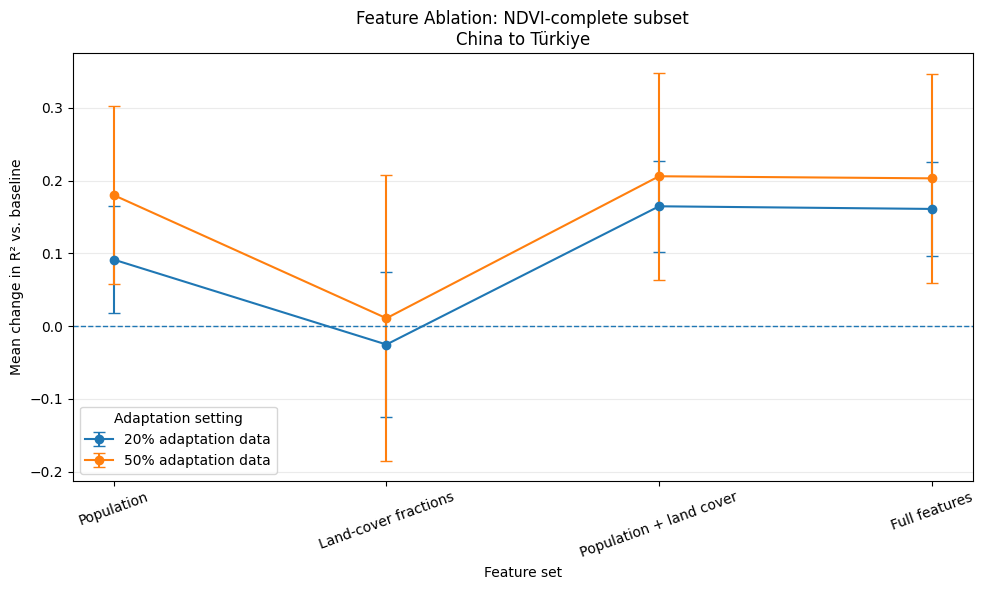

Saved figure: feature_ablation_NDVI_COMPLETE_SUBSET_China_to_Turkiye.png


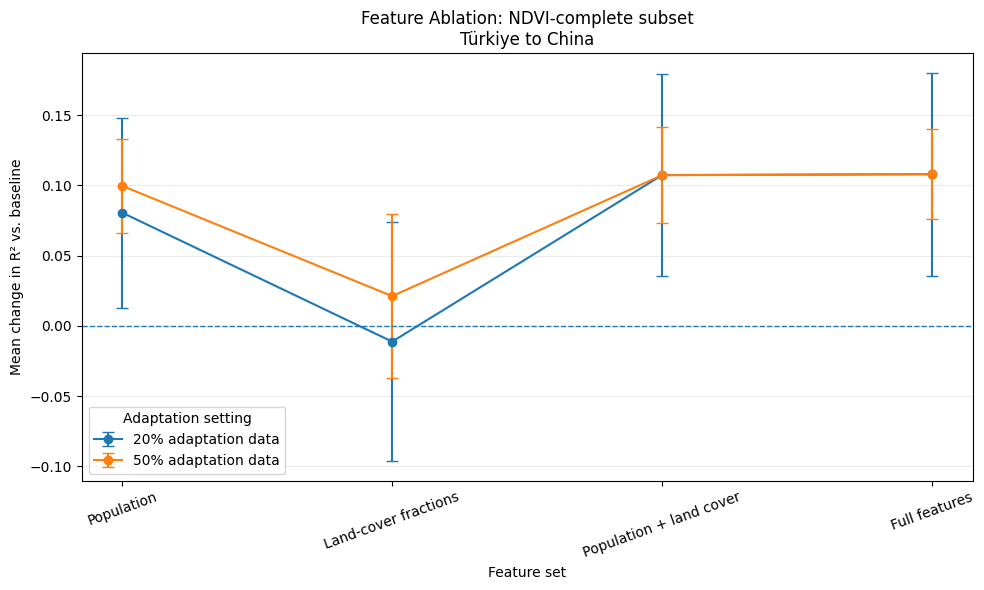

Saved figure: feature_ablation_NDVI_COMPLETE_SUBSET_Turkiye_to_China.png


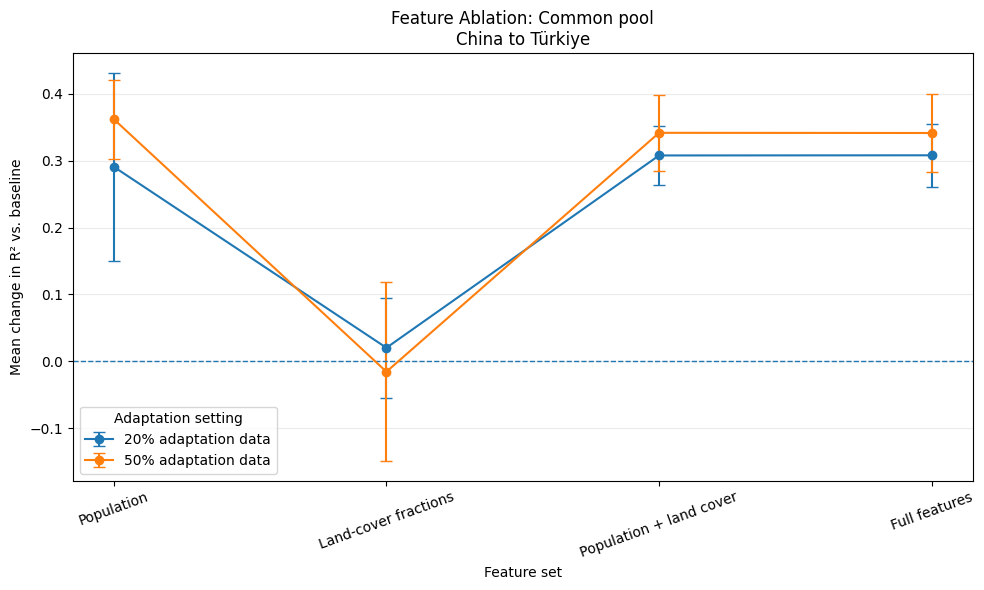

Saved figure: feature_ablation_PRIMARY_COMMON_POOL_China_to_Turkiye.png


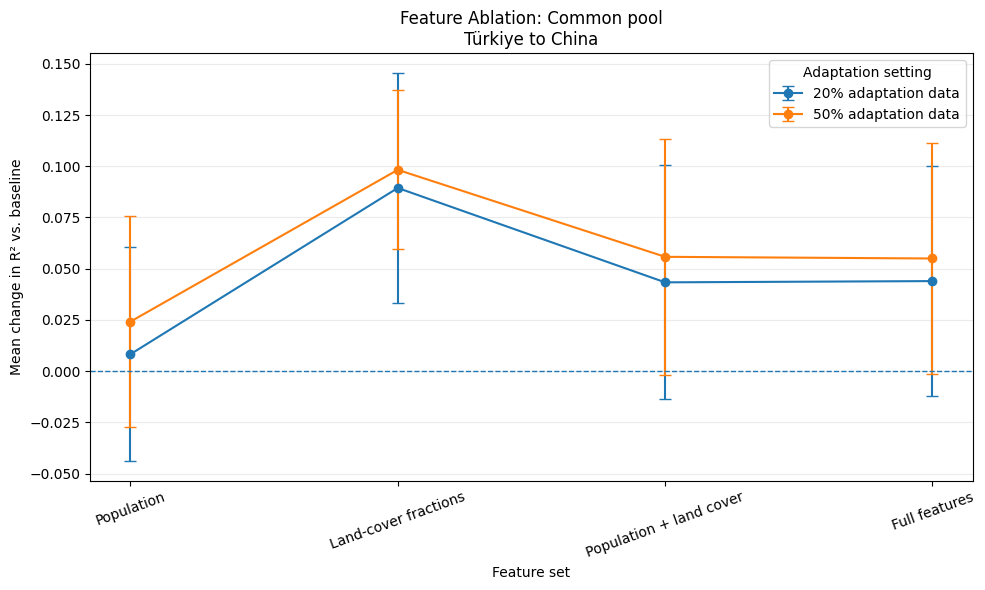

Saved figure: feature_ablation_PRIMARY_COMMON_POOL_Turkiye_to_China.png

Feature-ablation figures have been generated.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load the saved feature-ablation summary.
summary_path = ROOT / "task7_feature_ablation_summary.csv"
summary = pd.read_csv(summary_path)

required_columns = {
    "pool",
    "direction",
    "ratio",
    "variant",
    "paired_runs",
    "mean_delta_r2",
    "sd_delta_r2",
}

missing_columns = required_columns - set(summary.columns)

if missing_columns:
    raise ValueError(
        f"Missing required columns: {sorted(missing_columns)}"
    )

# Define readable labels for the report figures.
variant_labels = {
    "B_plus_population": "Population",
    "C_plus_landcover_fractions": "Land-cover fractions",
    "D_population_and_fractions": "Population + land cover",
    "E_full_with_landcover_category": "Full features",
}

pool_labels = {
    "PRIMARY_COMMON_POOL": "Common pool",
    "NDVI_COMPLETE_SUBSET": "NDVI-complete subset",
}

direction_labels = {
    "China_to_Turkiye": "China to Türkiye",
    "Turkiye_to_China": "Türkiye to China",
}

# Generate one figure for each pool and transfer direction.
for pool in sorted(summary["pool"].unique()):
    for direction in sorted(summary["direction"].unique()):
        subset = summary[
            (summary["pool"] == pool)
            & (summary["direction"] == direction)
        ].copy()

        if subset.empty:
            continue

        subset["variant_label"] = subset["variant"].map(
            variant_labels
        ).fillna(subset["variant"])

        subset = subset.sort_values(["ratio", "variant"])

        fig, ax = plt.subplots(figsize=(10, 6))

        for ratio in sorted(subset["ratio"].unique()):
            ratio_data = subset[subset["ratio"] == ratio]

            ax.errorbar(
                ratio_data["variant_label"],
                ratio_data["mean_delta_r2"],
                yerr=ratio_data["sd_delta_r2"],
                marker="o",
                capsize=4,
                linewidth=1.5,
                label=f"{ratio:.0%} adaptation data",
            )

        ax.axhline(0, linestyle="--", linewidth=1)
        ax.set_title(
            f"Feature Ablation: {pool_labels.get(pool, pool)}\n"
            f"{direction_labels.get(direction, direction)}"
        )
        ax.set_xlabel("Feature set")
        ax.set_ylabel("Mean change in R² vs. baseline")
        ax.tick_params(axis="x", rotation=20)
        ax.legend(title="Adaptation setting")
        ax.grid(axis="y", alpha=0.25)

        fig.tight_layout()

        output_name = (
            f"feature_ablation_{pool}_{direction}.png"
        )
        output_path = FIGURE_DIR / output_name

        fig.savefig(output_path, dpi=300, bbox_inches="tight")
        plt.show()
        plt.close(fig)

        print("Saved figure:", output_path.name)

print("\nFeature-ablation figures have been generated.")

## Results Under Extremely Limited Adaptation Data

This section examines model performance when only 1% of the available target-country adaptation data is used. The analysis compares the baseline feature set with population, land-cover, and combined feature sets.

The purpose is to assess whether the additional features remain useful when very little target-country data is available. Results are examined in both transfer directions and across the common data pool and the NDVI-complete subset.

The results are descriptive and should be interpreted in the context of the available sample sizes and variation across random seeds.

In [3]:

import pandas as pd
import matplotlib.pyplot as plt

results_path = ROOT / "task7_feature_ablation_1pct_performance.csv"
results = pd.read_csv(results_path)

print("Available columns:", results.columns.tolist())
print("Number of rows:", len(results))
display(results.head())


Available columns: ['pool', 'direction', 'variant', 'mean_r2', 'sd_r2', 'mean_rmse', 'mean_mae']
Number of rows: 16


,pool,direction,variant,mean_r2,sd_r2,mean_rmse,mean_mae
0,NDVI_COMPLETE_SUBSET,China_to_Turkiye,A_legacy,0.273504,0.079434,0.616332,0.505901
1,NDVI_COMPLETE_SUBSET,China_to_Turkiye,B_plus_population,0.439284,0.028046,0.541984,0.424757
2,NDVI_COMPLETE_SUBSET,China_to_Turkiye,C_plus_landcover,0.245032,0.027902,0.628978,0.503304
3,NDVI_COMPLETE_SUBSET,China_to_Turkiye,D_population_and_landcover,0.510822,0.024644,0.506230,0.388214
4,NDVI_COMPLETE_SUBSET,Turkiye_to_China,A_legacy,-0.072758,0.069881,0.479162,0.369394


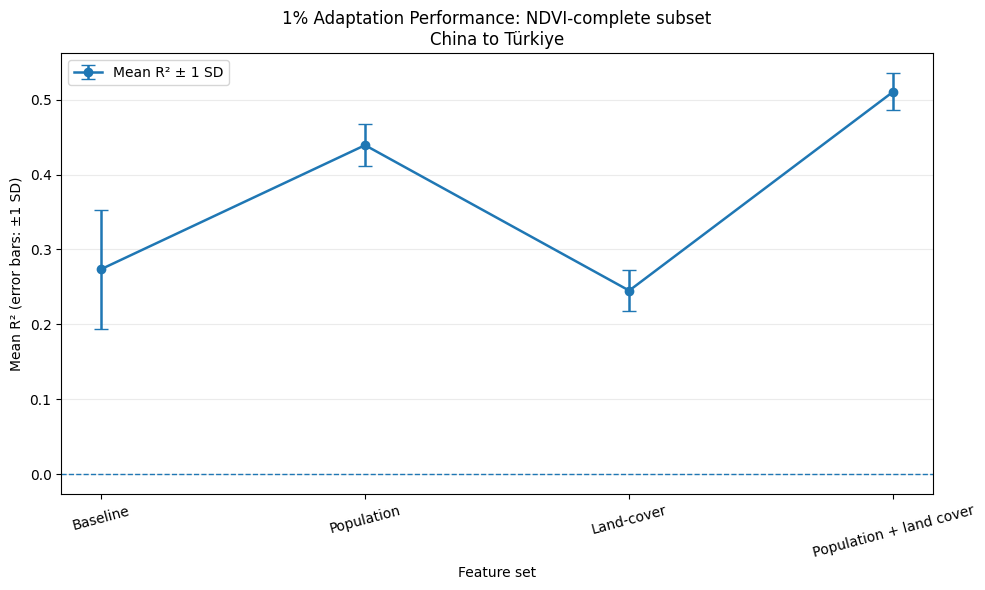

Saved figure: feature_ablation_1pct_NDVI_COMPLETE_SUBSET_China_to_Turkiye.png


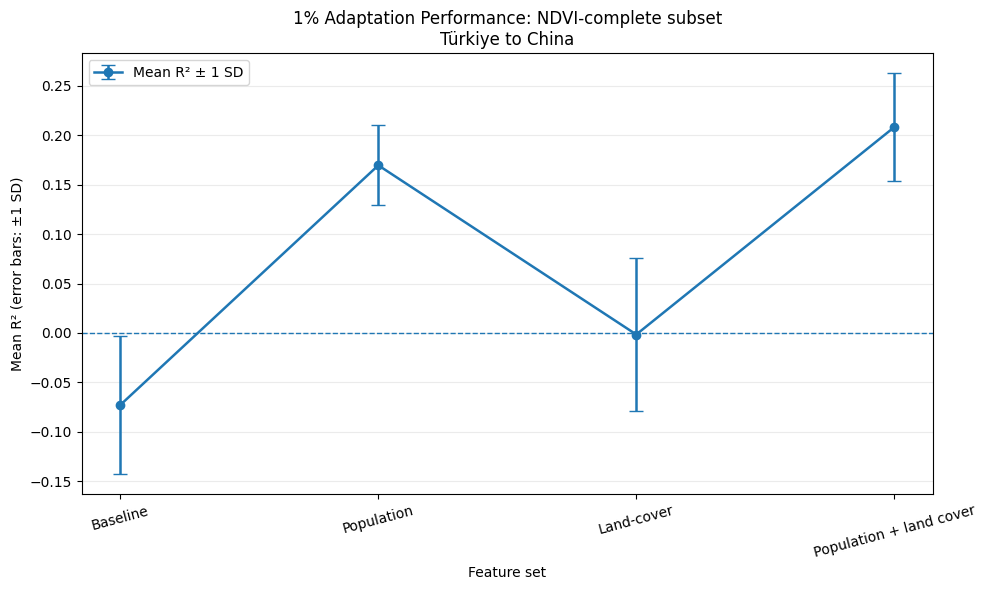

Saved figure: feature_ablation_1pct_NDVI_COMPLETE_SUBSET_Turkiye_to_China.png


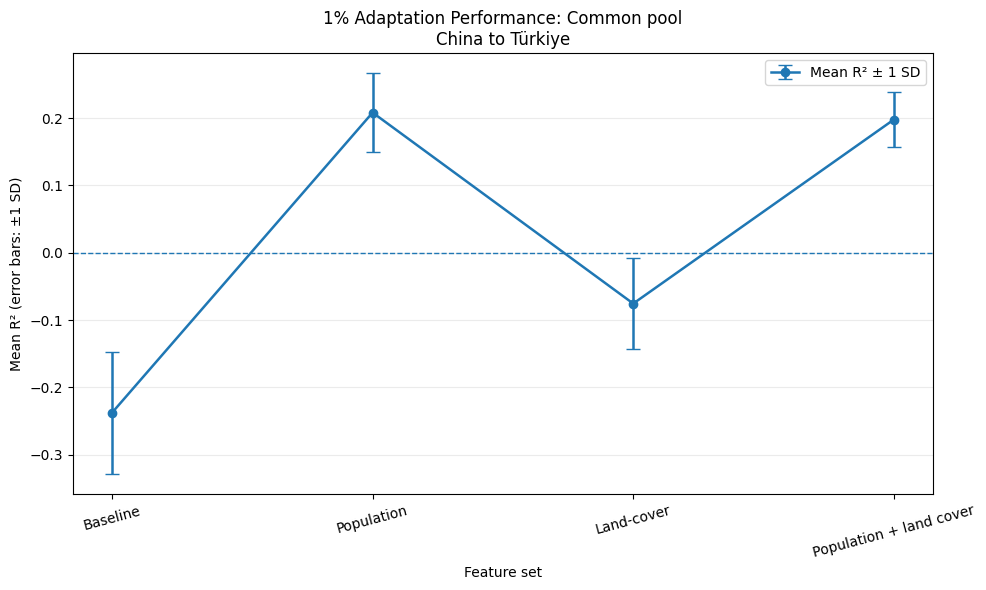

Saved figure: feature_ablation_1pct_PRIMARY_COMMON_POOL_China_to_Turkiye.png


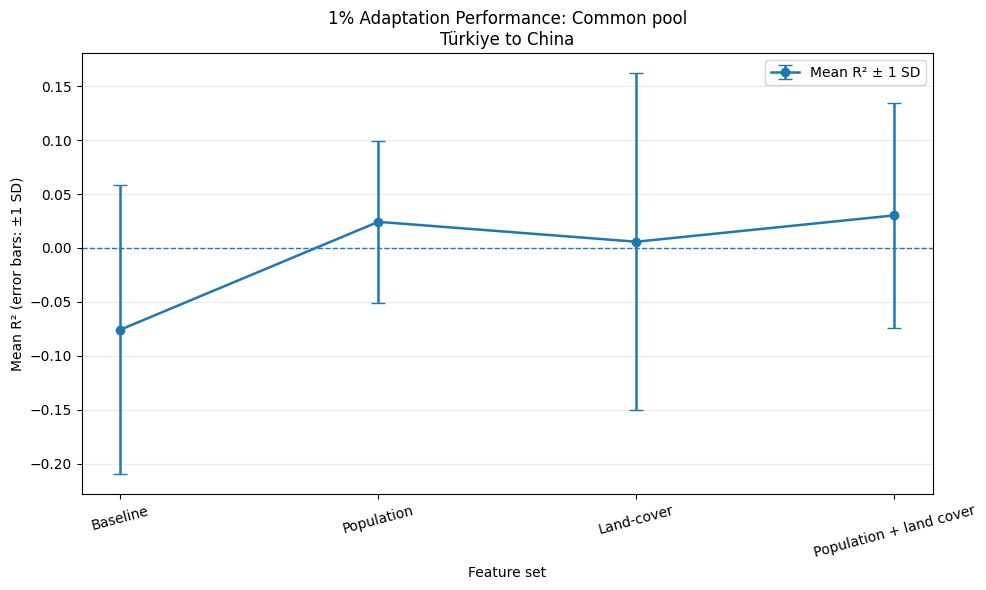

Saved figure: feature_ablation_1pct_PRIMARY_COMMON_POOL_Turkiye_to_China.png

All 1% adaptation figures have been generated.


In [4]:

import pandas as pd
import matplotlib.pyplot as plt

# Load the saved 1% adaptation performance results.
results_path = ROOT / "task7_feature_ablation_1pct_performance.csv"
results = pd.read_csv(results_path)

# Check that the required columns are available.
required_columns = {
    "pool", "direction", "variant",
    "mean_r2", "sd_r2", "mean_rmse", "mean_mae"
}
missing_columns = required_columns - set(results.columns)

if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

# Keep the feature sets in a consistent order across figures.
variant_order = [
    "A_legacy",
    "B_plus_population",
    "C_plus_landcover",
    "D_population_and_landcover",
]

variant_labels = {
    "A_legacy": "Baseline",
    "B_plus_population": "Population",
    "C_plus_landcover": "Land-cover",
    "D_population_and_landcover": "Population + land cover",
}

pool_labels = {
    "PRIMARY_COMMON_POOL": "Common pool",
    "NDVI_COMPLETE_SUBSET": "NDVI-complete subset",
}

direction_labels = {
    "China_to_Turkiye": "China to Türkiye",
    "Turkiye_to_China": "Türkiye to China",
}

# Generate one figure for each data pool and transfer direction.
for (pool, direction), subset in results.groupby(["pool", "direction"]):

    subset = subset.copy()
    subset["variant"] = pd.Categorical(
        subset["variant"],
        categories=variant_order,
        ordered=True
    )
    subset = subset.sort_values("variant")

    # Confirm that all expected feature sets are present.
    if subset["variant"].isna().any() or len(subset) != len(variant_order):
        raise ValueError(
            f"Unexpected feature-set structure for {pool}, {direction}"
        )

    labels = [variant_labels[v] for v in subset["variant"].astype(str)]

    fig, ax = plt.subplots(figsize=(10, 6))

    # Error bars represent one standard deviation across random seeds.
    ax.errorbar(
        labels,
        subset["mean_r2"],
        yerr=subset["sd_r2"],
        marker="o",
        capsize=5,
        linewidth=1.8,
        label="Mean R² ± 1 SD"
    )

    # R² below zero indicates performance worse than predicting the test-set mean.
    ax.axhline(0, linestyle="--", linewidth=1)

    ax.set_title(
        f"1% Adaptation Performance: {pool_labels.get(pool, pool)}\n"
        f"{direction_labels.get(direction, direction)}"
    )
    ax.set_xlabel("Feature set")
    ax.set_ylabel("Mean R² (error bars: ±1 SD)")
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.25)
    ax.legend()
    fig.tight_layout()

    output_name = f"feature_ablation_1pct_{pool}_{direction}.png"
    output_path = FIGURE_DIR / output_name

    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Saved figure:", output_path.name)

print("\nAll 1% adaptation figures have been generated.")


## Error-Based Evaluation: RMSE and MAE

R² measures how well a model explains variation in the target variable. However, it does not describe prediction errors on its own. This section therefore evaluates Root Mean Squared Error (RMSE) and Mean Absolute Error (MAE) alongside R².

RMSE gives greater weight to larger prediction errors, while MAE measures the average absolute difference between predicted and observed values. For both metrics, lower values indicate better predictive performance when models are evaluated on the same test data.

The analysis compares four feature sets under the 1% adaptation setting:

- **Baseline:** the original feature set.
- **Population:** the baseline with population information.
- **Land-cover:** the baseline with land-cover information.
- **Population + land cover:** the baseline with both additional feature groups.

Results are examined across both transfer directions and both data pools. This comparison helps determine whether improvements in R² are accompanied by lower prediction errors.

The reported values are averages across the saved experiment runs. Differences should be interpreted descriptively and in combination with the variation across runs, rather than as proof of statistical significance.

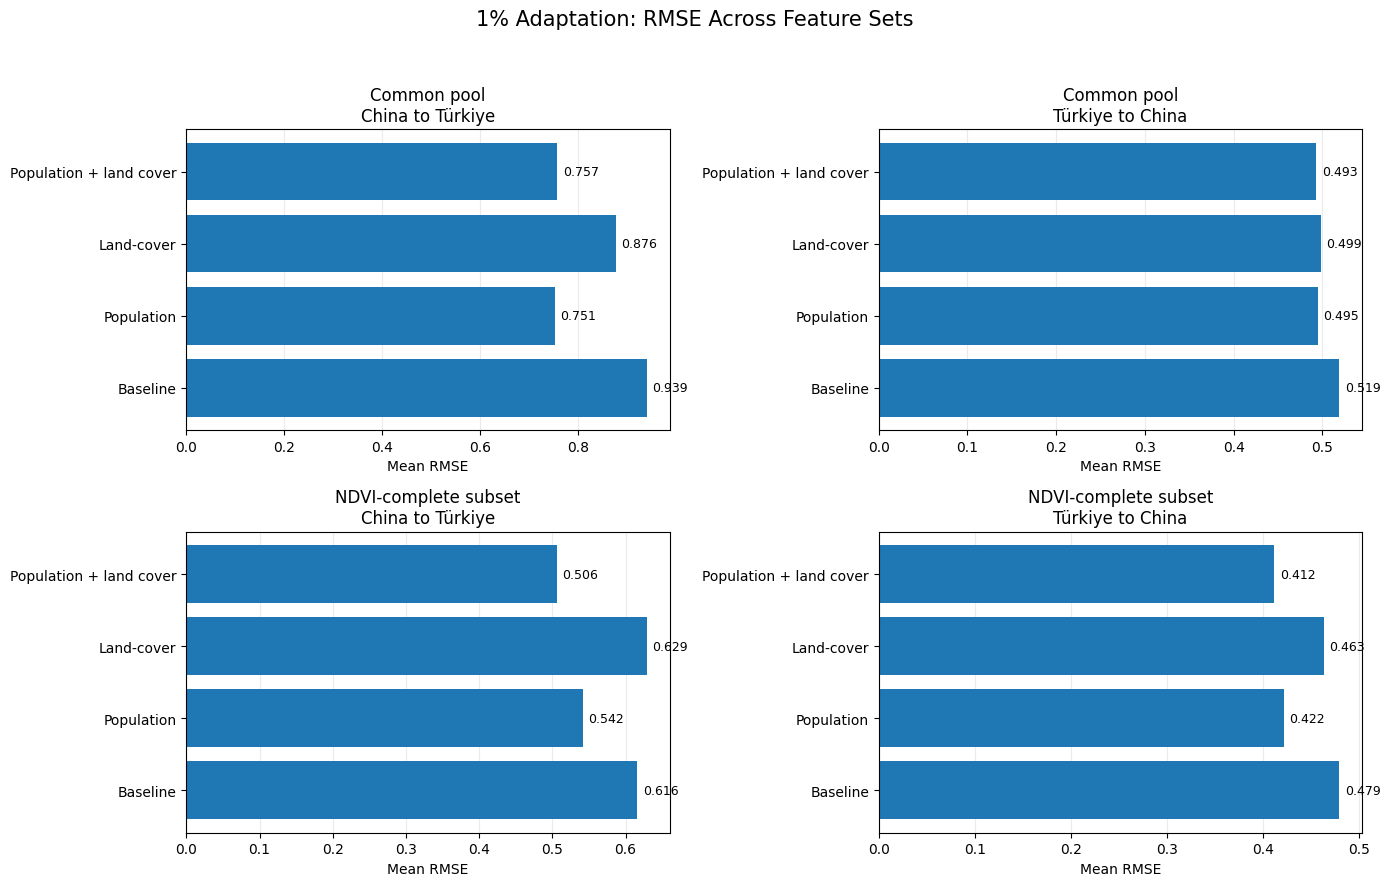

Saved figure: feature_ablation_1pct_rmse.png


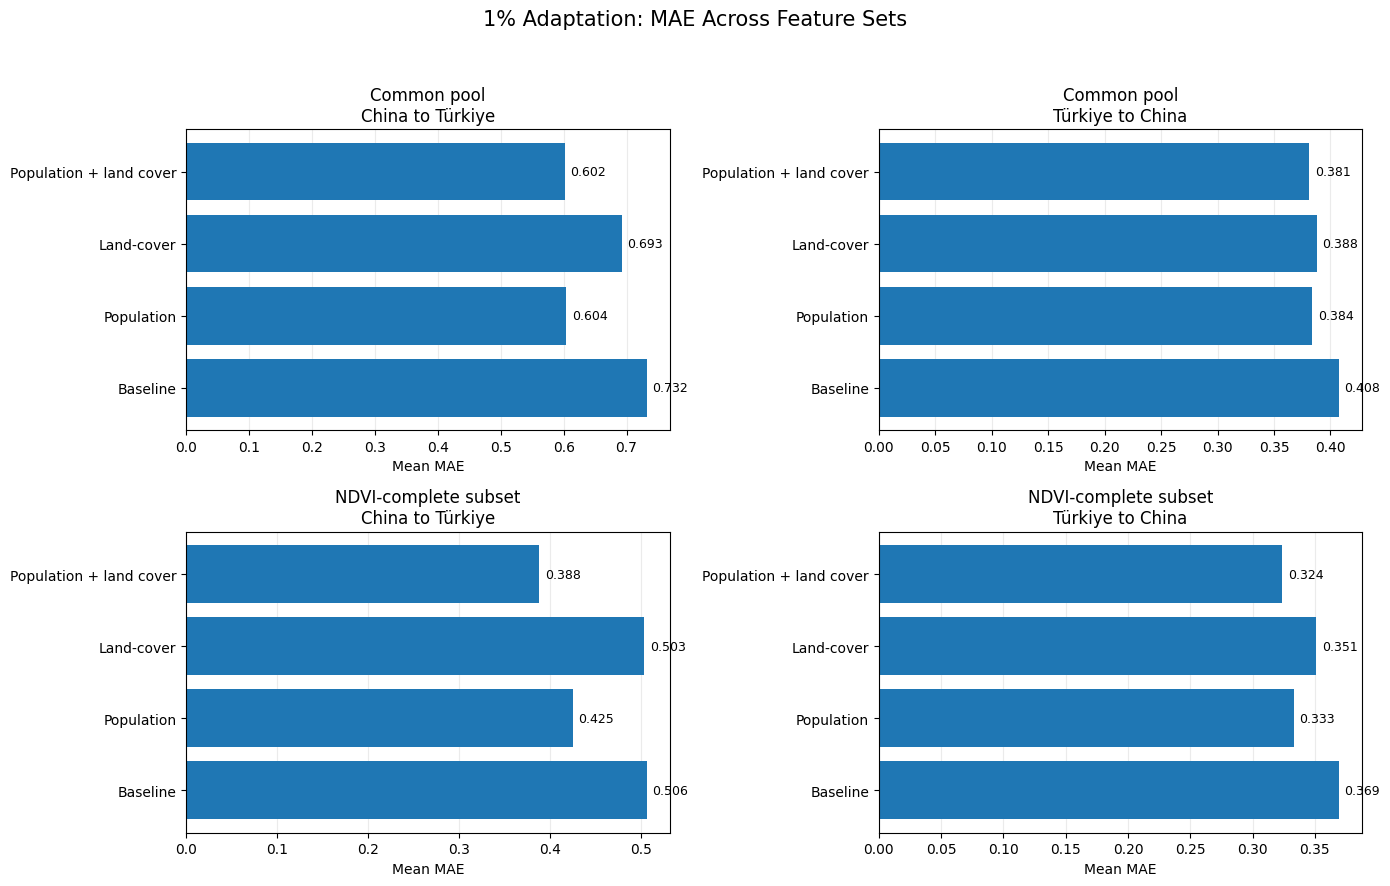

Saved figure: feature_ablation_1pct_mae.png

RMSE and MAE figures have been generated.


In [5]:

import pandas as pd
import matplotlib.pyplot as plt

# Load the saved 1% adaptation results.
results_path = ROOT / "task7_feature_ablation_1pct_performance.csv"
results = pd.read_csv(results_path)

variant_order = [
    "A_legacy",
    "B_plus_population",
    "C_plus_landcover",
    "D_population_and_landcover",
]

variant_labels = {
    "A_legacy": "Baseline",
    "B_plus_population": "Population",
    "C_plus_landcover": "Land-cover",
    "D_population_and_landcover": "Population + land cover",
}

pool_labels = {
    "PRIMARY_COMMON_POOL": "Common pool",
    "NDVI_COMPLETE_SUBSET": "NDVI-complete subset",
}

direction_labels = {
    "China_to_Turkiye": "China to Türkiye",
    "Turkiye_to_China": "Türkiye to China",
}

# Create one figure for each error metric.
for metric in ["mean_rmse", "mean_mae"]:

    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    axes = axes.flatten()

    scenarios = [
        ("PRIMARY_COMMON_POOL", "China_to_Turkiye"),
        ("PRIMARY_COMMON_POOL", "Turkiye_to_China"),
        ("NDVI_COMPLETE_SUBSET", "China_to_Turkiye"),
        ("NDVI_COMPLETE_SUBSET", "Turkiye_to_China"),
    ]

    for ax, (pool, direction) in zip(axes, scenarios):

        subset = results[
            (results["pool"] == pool) &
            (results["direction"] == direction)
        ].copy()

        subset["variant"] = pd.Categorical(
            subset["variant"],
            categories=variant_order,
            ordered=True
        )
        subset = subset.sort_values("variant")

        if len(subset) != len(variant_order) or subset[metric].isna().any():
            raise ValueError(
                f"Missing or incomplete results for {pool}, {direction}"
            )

        labels = [
            variant_labels[str(variant)]
            for variant in subset["variant"]
        ]

        values = subset[metric].tolist()

        bars = ax.barh(labels, values)

        ax.set_title(
            f"{pool_labels[pool]}\n{direction_labels[direction]}"
        )
        ax.set_xlabel("Mean RMSE" if metric == "mean_rmse" else "Mean MAE")
        ax.grid(axis="x", alpha=0.25)
        ax.set_axisbelow(True)

        # Display each mean error value beside its bar.
        for bar, value in zip(bars, values):
            ax.annotate(
                f"{value:.3f}",
                xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(4, 0),
                textcoords="offset points",
                va="center",
                fontsize=9
            )

    metric_name = "RMSE" if metric == "mean_rmse" else "MAE"
    fig.suptitle(
        f"1% Adaptation: {metric_name} Across Feature Sets",
        fontsize=15
    )
    fig.tight_layout(rect=[0, 0, 1, 0.95])

    output_path = FIGURE_DIR / f"feature_ablation_1pct_{metric_name.lower()}.png"
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Saved figure:", output_path.name)

print("\nRMSE and MAE figures have been generated.")


## Results and Discussion

### 1. Results with 1% Adaptation Data

The 1% adaptation experiments examine whether additional population and land-cover information can improve cross-country predictions when only a very small amount of target-country data is available. The results are compared across two data pools and both transfer directions.

#### Population Information

Population information improved model performance in all four scenarios. The improvement was especially clear for China-to-Türkiye transfer in the common pool. In this setting, the baseline achieved an R² of -0.238, while adding population increased it to 0.208. RMSE decreased from 0.939 to 0.751, and MAE decreased from 0.732 to 0.604.

Population information also improved performance in the other three scenarios. These results suggest that population-related information can be useful for cross-country prediction under limited adaptation data.

#### Land-Cover Information

Land-cover information alone did not perform as well as population information in these experiments. Its R² remained negative in two scenarios and was close to zero in another. It also produced higher RMSE and MAE values than the population-based model in all four scenarios.

These results suggest that land-cover fractions alone may not provide enough predictive information under the tested conditions. However, this does not mean that land-cover information has no value when combined with other features.

#### Combining Population and Land-Cover Information

Combining population and land-cover information produced the best mean results in three of the four scenarios when considering R², RMSE, and MAE together.

For the NDVI-complete subset, the combined feature set achieved an R² of 0.511 for China-to-Türkiye transfer and 0.208 for Türkiye-to-China transfer. These were the highest R² values among the four feature sets in their respective scenarios.

The combined feature set also achieved the lowest RMSE and MAE values in both transfer directions for the NDVI-complete subset. In the common pool, it performed best for Türkiye-to-China transfer. However, for China-to-Türkiye transfer in the common pool, population alone achieved a slightly higher R² (0.208 compared with 0.198) and a slightly lower RMSE (0.751 compared with 0.757). The combined model achieved a marginally lower MAE (0.602 compared with 0.604).

This difference shows that adding more features does not guarantee an improvement in every evaluation metric. The best feature set can depend on the data pool, transfer direction, and metric being considered.

### 2. Comparison Across Data Pools and Transfer Directions

The results differ between the common pool and the NDVI-complete subset. In the NDVI-complete subset, the combined feature set achieved stronger R² results in both transfer directions. In the common pool, its advantage was smaller and depended on the transfer direction.

The two transfer directions also produced different results. This indicates that transfer performance is not necessarily symmetric: a feature set that works well when transferring from China to Türkiye may not produce the same relative improvement when transferring from Türkiye to China.

These findings support evaluating both transfer directions separately rather than treating cross-country transfer as a single uniform task.

### 3. Main Findings

The 1% adaptation experiments provide three main observations:

1. Population information was consistently useful across the four scenarios.
2. Land-cover information alone generally performed less well than population information.
3. Combining population and land-cover information often produced the strongest overall results, but the improvement was not universal across all metrics and scenarios.

These findings are descriptive. The mean values summarize the saved experiment runs, but the observed differences should not be interpreted as statistically significant without additional statistical testing.

### 4. Limitations of This Evaluation

The experiments evaluate performance under the specific data pools, feature definitions, adaptation settings, and random seeds used in this study. The 1% setting also represents a highly limited adaptation-data condition, so results may be sensitive to which observations are selected.

The RMSE and MAE figures show mean values but do not display variation across runs. In addition, the current comparisons do not establish that the observed differences are statistically significant or that any feature has a causal effect on urban climate outcomes.

The findings should therefore be interpreted as evidence of predictive performance under the tested conditions. Further validation would be needed before generalizing them to other countries, datasets, or modelling settings.

## Conclusion

This study examined how urban climate models transfer between China and Türkiye and whether additional population and land-cover information can improve their performance. Using city-year data from 2001 to 2020, the analysis compared different feature sets under several adaptation settings, with a particular focus on situations where only a small amount of target-country data is available.

The results show that population information can make a useful contribution to cross-country prediction. In the 1% adaptation experiments, adding population improved R² in all four combinations of data pool and transfer direction. The improvement was particularly clear when transferring from China to Türkiye using the common data pool, where the baseline R² increased from -0.238 to 0.208.

Combining population and land-cover information also produced promising results. The combined feature set achieved the highest mean R² in three of the four 1% adaptation scenarios and generally reduced prediction errors compared with the baseline. However, the results were not identical across all scenarios. For China-to-Türkiye transfer in the common pool, population alone achieved a slightly higher R² and lower RMSE than the combined feature set. This suggests that adding more features does not always lead to better predictions.

The experiments also showed differences between the two transfer directions and between the common pool and the NDVI-complete subset. These differences matter because a model that performs well in one direction may not perform equally well in the other. Evaluating both directions therefore provides a more complete picture of how well the selected features support cross-country transfer.

Overall, the findings suggest that population information is a useful addition to the tested feature sets, while the value of land-cover information depends on the wider combination of features and the evaluation setting. The results provide a starting point for studying how urban climate models can be adapted to countries where detailed local data are limited.

There are several limitations to consider. The analysis covers two countries and depends on the available city-year observations, feature coverage, and adaptation samples. The reported differences are descriptive and have not, by themselves, established statistical significance or causal relationships. Further testing with additional countries, alternative model settings, and formal statistical comparisons would help determine how consistently these findings apply beyond the experiments conducted here.

Despite these limitations, this study provides a structured comparison of feature sets and transfer directions. It highlights the potential value of population data and shows why feature selection should be evaluated under different data conditions rather than assumed to work equally well in every setting.